# Comprehensive Quantitative Analysis of Indian Stock Indices (2005 - 2026)

This Jupyter Notebook provides a rigorous quantitative walk-through of the performance, risk metrics, and correlations of **41 Indian stock indices (broad-market, alternative-weighting and strategic factor indices)** from **April 1, 2005 to October 16, 2026** (a 21.5-year period).

## 1. Project Overview & Scope
Unlike standard analyses that use simple Price Return Indices (which ignore dividends), this study uses the **Total Return Index (TRI)** data. Dividends represent a massive portion of long-term wealth compounding in India, and incorporating them is essential for accurate CAGR, Sharpe, and Sortino calculations.

### Indices Covered
We analyze **41 indices**, all with complete TRI histories from April 2005:
- **Broad-Based (8):** Nifty 50, Nifty Next 50, Nifty 500, Nifty Midcap 150, Nifty Smallcap 250, Nifty Smallcap 500, Nifty Microcap 250, Nifty Total Market.
- **Alternative weighting (6):** Nifty50 / Nifty100 / Nifty500 Equal Weight, Nifty500 LargeMidSmall Equal-Cap Weighted, Nifty500 Multicap 50:25:25, Nifty MidSmallcap400 50:50.
- **Strategic & Factor-Based (27):** Momentum, Quality, Value, Low Volatility, Alpha, Growth, High Dividend Yield, High Beta and multi-factor combinations across the Nifty 50/100/200/500, Midcap150, Smallcap250, MidSmallcap400 and Total Market universes (every NSE strategy index with history back to April 2005; see `reference/nse_equity_indices.csv`).

*(Indices that start later, such as Nifty100 Quality 30, Nifty50 Value 20 and Nifty500 Flexicap Quality 30, are omitted so that every series covers the same period.)*

---

## 2. Environment Setup & Data Loading
Let's import our libraries and load the pre-downloaded, cleaned historical TRI dataset. We will merge all 19 index files on the `Date` column, forward-fill any minor date alignment gaps, and resample the daily data to **weekly signals (using Friday close)** to avoid short-term trading noise.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

# Constants
RF_RATE = 0.06  # Annualized 6% Risk-Free Rate for India
DATA_DIR = "data"
OUTPUT_DIR = "results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Plotting config
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

print("Libraries successfully imported!")

Libraries successfully imported!


In [2]:
def load_merged_data():
    files = glob.glob(os.path.join(DATA_DIR, "*_TRI.csv"))
    if not files:
        raise ValueError("No TRI data files found! Please run the download script first.")
        
    dfs = []
    for f in files:
        temp_df = pd.read_csv(f)
        temp_df['Date'] = pd.to_datetime(temp_df['Date'])
        dfs.append(temp_df)
        
    # Outer merge on Date
    master_df = dfs[0]
    for df in dfs[1:]:
        master_df = pd.merge(master_df, df, on='Date', how='outer')
        
    master_df = master_df.sort_values('Date').reset_index(drop=True)
    master_df.set_index('Date', inplace=True)
    
    # Forward and backward fill minor holiday gaps
    master_df = master_df.ffill().bfill()
    return master_df

df_daily = load_merged_data()
print(f"Successfully loaded master dataset!")
print(f"Date Range: {df_daily.index.min().strftime('%Y-%m-%d')} to {df_daily.index.max().strftime('%Y-%m-%d')} ({len(df_daily)} trading days)")
print(f"Number of Indices loaded: {len(df_daily.columns)}")

Successfully loaded master dataset!
Date Range: 2005-04-01 to 2026-10-16 (5344 trading days)
Number of Indices loaded: 41


## 3. Quantitative Metric Calculations
We will compute the following standard quantitative finance metrics for each index:
1. **Compound Annual Growth Rate (CAGR):** Annual compounded rate of return.
2. **Annualized Volatility (Standard Deviation):** Standard deviation of weekly returns scaled by $\sqrt{52}$.
3. **Sharpe Ratio:** Reward-to-variability ratio, calculated using a 6% risk-free rate.
4. **Annualized Downside Deviation:** Standard deviation of weekly returns strictly below 0 (for Sortino ratio).
5. **Sortino Ratio:** Risk-adjusted return penalizing *only* downside/negative returns.
6. **Maximum Drawdown (Max DD):** Peak-to-trough drop from daily price records.

In [3]:
def run_metrics_analysis(df, rf_rate=0.06):
    metrics = {}
    years = (df.index[-1] - df.index[0]).days / 365.25
    
    # Weekly Friday close resampling
    df_weekly = df.resample('W').last()
    returns_weekly = df_weekly.pct_change().dropna()
    
    for col in df.columns:
        p_start = df[col].iloc[0]
        p_end = df[col].iloc[-1]
        
        # 1. CAGR
        cagr = (p_end / p_start) ** (1 / years) - 1
        
        # 2. Volatility (weekly annualized)
        weekly_std = returns_weekly[col].std()
        vol = weekly_std * np.sqrt(52)
        
        # 3. Sharpe
        sharpe = (cagr - rf_rate) / vol if vol > 0 else np.nan
        
        # 4. Sortino (downside vol annualized)
        neg_ret = returns_weekly[col].copy()
        neg_ret[neg_ret > 0] = 0
        downside_std = np.sqrt(np.mean(neg_ret ** 2))
        downside_vol = downside_std * np.sqrt(52)
        sortino = (cagr - rf_rate) / downside_vol if downside_vol > 0 else np.nan
        
        # 5. Max Drawdown (calculated on daily data for high precision)
        running_max = df[col].cummax()
        drawdowns = (df[col] - running_max) / running_max
        max_dd = drawdowns.min()
        
        metrics[col] = {
            "CAGR (%)": cagr * 100,
            "Volatility (%)": vol * 100,
            "Sharpe Ratio": sharpe,
            "Sortino Ratio": sortino,
            "Max Drawdown (%)": max_dd * 100
        }
        
    return pd.DataFrame(metrics).T

metrics_df = run_metrics_analysis(df_daily, RF_RATE)
metrics_df = metrics_df.sort_values("Sortino Ratio", ascending=False)

print("=== Quantitative Metrics (Sorted by Sortino Ratio) ===")

=== Quantitative Metrics (Sorted by Sortino Ratio) ===


In [4]:
metrics_df.sort_values(by='CAGR (%)', ascending=False)

,CAGR (%),Volatility (%),Sharpe Ratio,Sortino Ratio,Max Drawdown (%)
Nifty Midcap150 Momentum 50,22.142762,22.040055,0.732428,1.076669,-72.521913
Nifty MidSmallcap400 Momentum Quality 100,21.361893,21.468694,0.715549,1.051891,-68.038423
Nifty Smallcap250 Momentum Quality 100,21.313102,24.323728,0.629554,0.923192,-72.434952
Nifty500 Momentum 50,21.251489,22.684235,0.672339,0.985507,-70.243232
Nifty Total Market Momentum Quality 50,20.375028,19.049677,0.754607,1.112004,-59.036881
Nifty500 Multicap Momentum Quality 50,20.076298,18.987138,0.741360,1.087741,-60.062250
Nifty High Dividend Yield 15,19.511389,24.777534,0.545308,0.856928,-56.842044
Nifty500 Multifactor MQVLv 50,19.031424,17.450908,0.746748,1.112816,-53.925022
Nifty Alpha 50,18.769416,25.101219,0.508717,0.716658,-78.875995
Nifty500 Growth 50,18.484674,24.531433,0.508926,0.739030,-76.152791


## 4. Performance Interpretation & Visualizations
Let's visualize the compounding growth of these indices. We normalize all indices to start at a base of 100 on **April 1, 2005** and plot them on a logarithmic scale to account for the immense growth over the 21-year period.

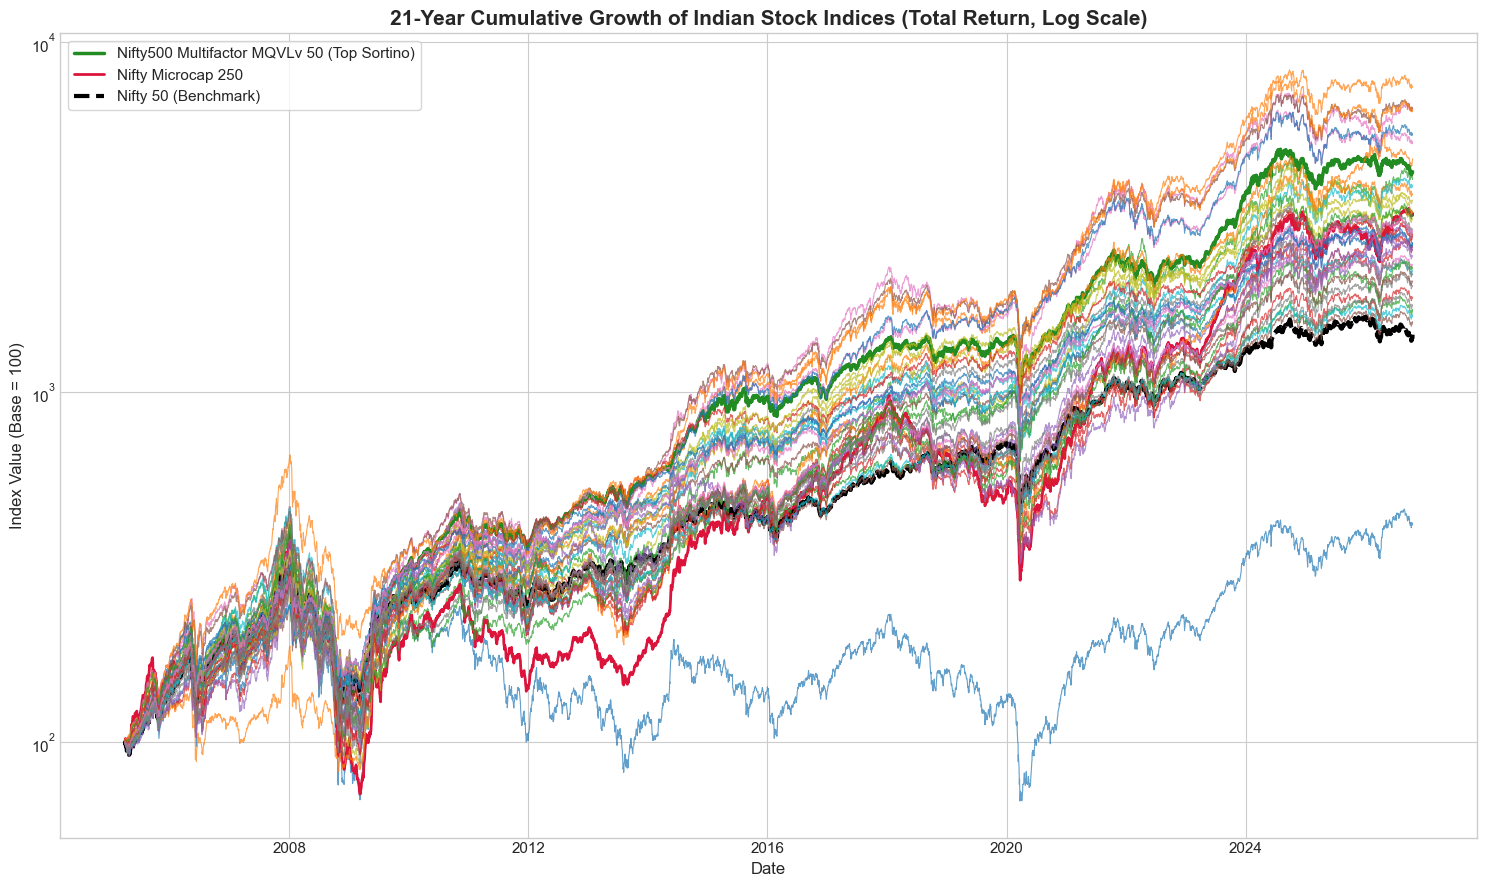

In [5]:
plt.figure(figsize=(15, 9))
df_norm = (df_daily / df_daily.iloc[0]) * 100

# Highlight the best strategic index, Nifty 50 benchmark, and Microcap
for col in df_norm.columns:
    if col == "Nifty 50":
        plt.plot(df_norm.index, df_norm[col], label=f"{col} (Benchmark)", linewidth=3.0, color='black', linestyle='--')
    elif col == metrics_df.index[0]:
        plt.plot(df_norm.index, df_norm[col], label=f"{col} (Top Sortino)", linewidth=2.5, color='forestgreen')
    elif col == "Nifty Microcap 250":
        plt.plot(df_norm.index, df_norm[col], label=f"{col}", linewidth=2.0, color='crimson')
    else:
        plt.plot(df_norm.index, df_norm[col], linewidth=0.8, alpha=0.7)
        
plt.yscale('log')
plt.title("21-Year Cumulative Growth of Indian Stock Indices (Total Return, Log Scale)", fontsize=15, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Index Value (Base = 100)", fontsize=12)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "cumulative_returns_all_log.png"), dpi=300)
plt.show()

## 5. Correlation & Overlap Analysis
We calculate the Pearson correlation matrix based on weekly returns to understand how these indices move together. 

Many broad indices (Nifty 50, Nifty 100, Nifty 500, Nifty Total Market) have massive overlaps. In contrast, strategic indices (like Momentum, Quality, and Value) offer factor tilts that can provide lower correlation and strong diversification benefits.

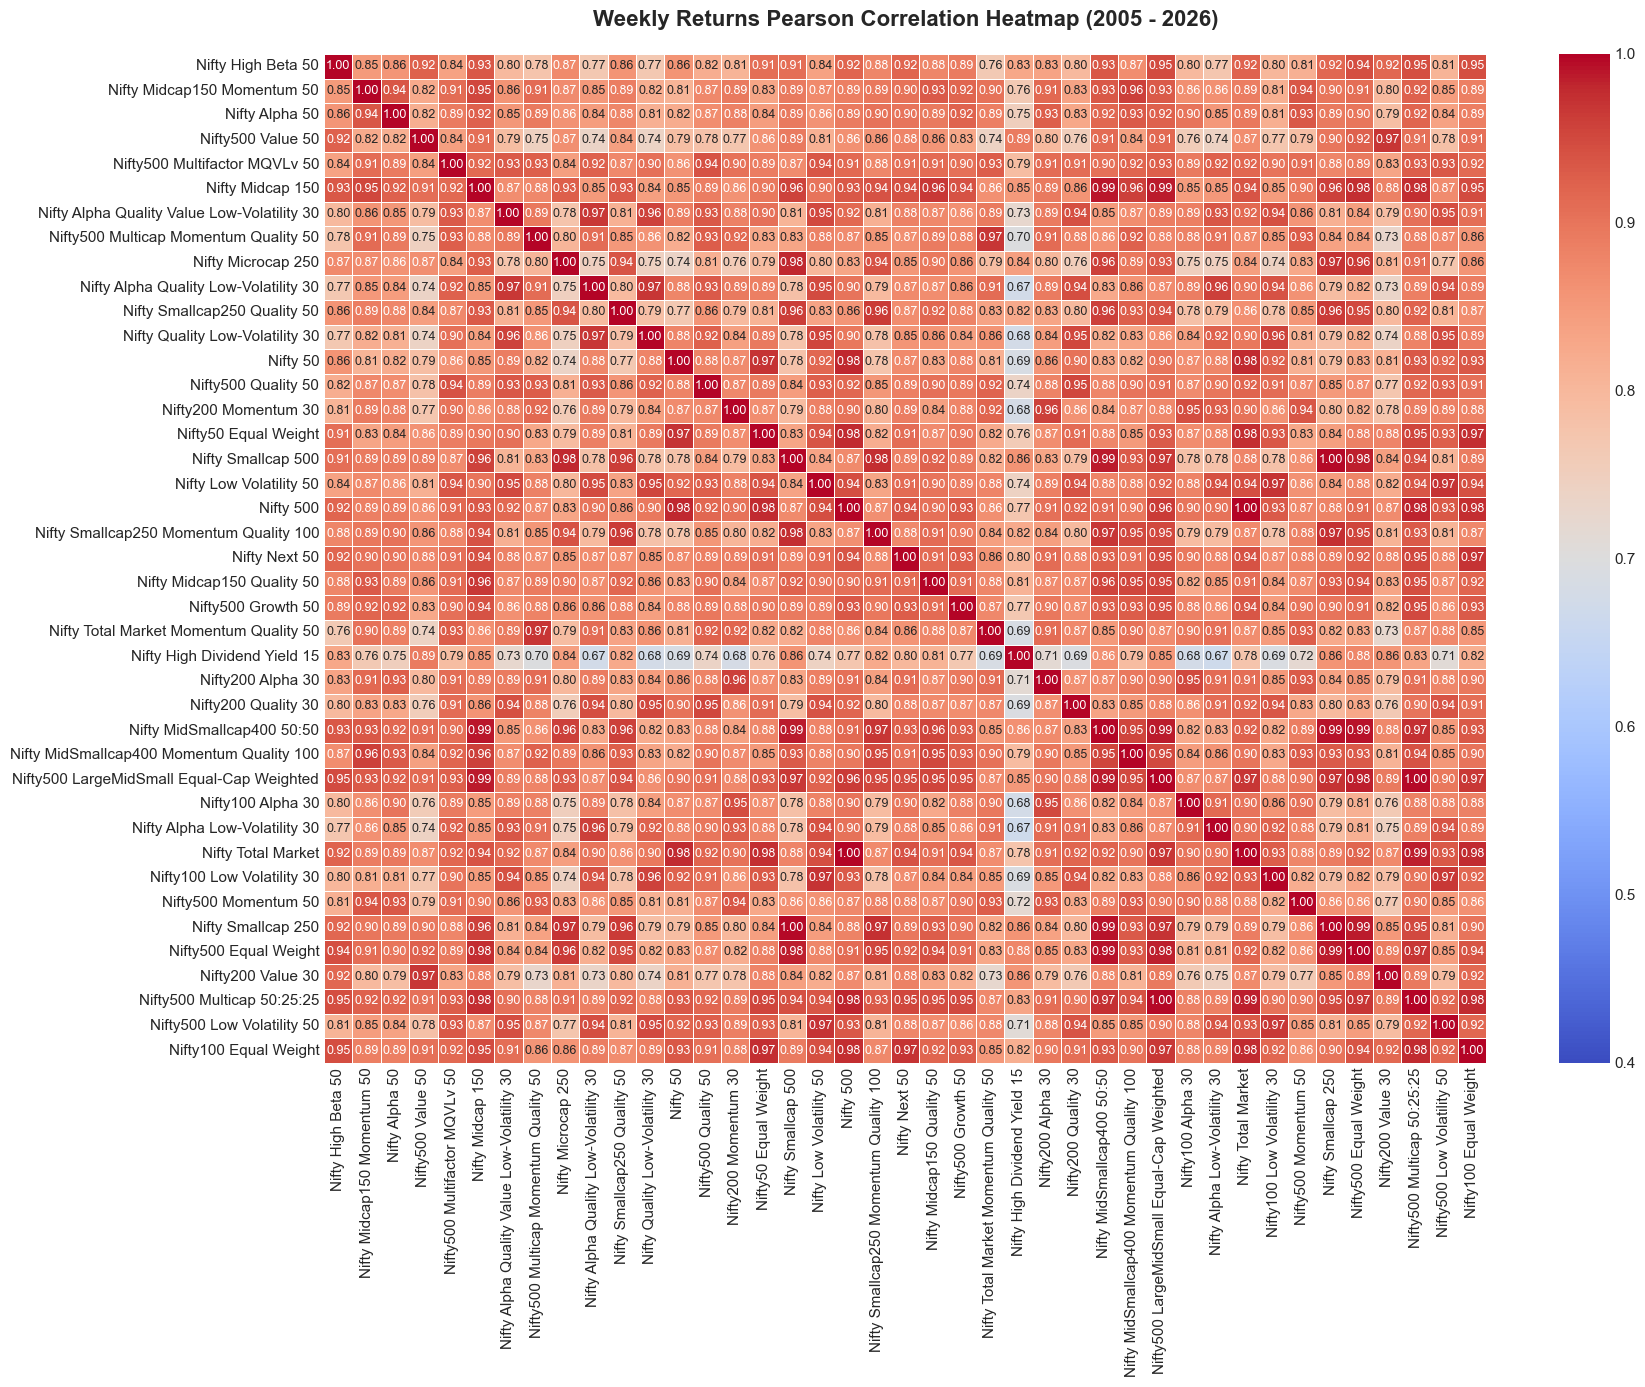

In [6]:
df_weekly = df_daily.resample('W').last()
returns_weekly = df_weekly.pct_change().dropna()

corr_matrix = returns_weekly.corr(method='pearson')

# Heatmap
plt.figure(figsize=(18, 14))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    vmin=0.4, vmax=1.0, 
    fmt=".2f", 
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title("Weekly Returns Pearson Correlation Heatmap (2005 - 2026)", fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "correlation_heatmap_all.png"), dpi=300)
plt.show()

## 6. Combining Indices for a Superior Sortino Ratio
The user wanted us to **combine multiple indices** to try to find a combination with a better Sortino ratio. 

We will do a **multi-factor portfolio optimization**. We select three complimentary factor indices from the high-performing **Nifty 500 Factor** universe:
1. **Momentum:** `Nifty500 Momentum 50` (strong absolute growth)
2. **Quality:** `Nifty500 Quality 50` (fundamentally strong, stable cash-flows)
3. **Low Volatility:** `Nifty500 Low Volatility 50` (defensive, low downside risk)

We will write an optimization algorithm to search for the weight combination ($w_1, w_2, w_3$) that **maximizes the Sortino ratio**.

In [7]:
# Filter down returns to the three factor pillars
factors = ["Nifty500 Momentum 50", "Nifty500 Quality 50", "Nifty500 Low Volatility 50"]
returns_factors = returns_weekly[factors]

# Equal-Weighted Combination
ew_returns = returns_factors.mean(axis=1)

# Function to calculate Sortino ratio of a weighted portfolio
def portfolio_sortino(weights, returns, rf_rate=0.06):
    weights = np.array(weights)
    weights = weights / np.sum(weights) # enforce sum to 1
    
    port_ret_series = returns.dot(weights)
    
    # Ann CAGR
    ann_ret = np.mean(port_ret_series) * 52
    
    # Ann Downside Std
    neg_ret = port_ret_series.copy()
    neg_ret[neg_ret > 0] = 0
    downside_std = np.sqrt(np.mean(neg_ret ** 2)) * np.sqrt(52)
    
    # Sortino (weekly returns based)
    sortino = (ann_ret - rf_rate) / downside_std if downside_std > 0 else 0
    return -sortino # negative for minimization

# Optimize weights
init_weights = [1/3, 1/3, 1/3]
bounds = ((0, 1), (0, 1), (0, 1))
constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}

opt_res = minimize(
    portfolio_sortino, 
    init_weights, 
    args=(returns_factors, RF_RATE), 
    bounds=bounds, 
    constraints=constraints
)

opt_weights = opt_res.x
print("=== Optimal Sortino Portfolio Weights ===")
for f, w in zip(factors, opt_weights):
    print(f"{f}: {w*100:.2f}%")

# Simulate equal-weight and optimal portfolio prices
factor_prices = df_daily[factors]
norm_prices = factor_prices / factor_prices.iloc[0]

# Equal-Weight Prices
ew_portfolio_prices = norm_prices.mean(axis=1) * 100

# Optimal Portfolio Prices
opt_portfolio_prices = norm_prices.dot(opt_weights) * 100

=== Optimal Sortino Portfolio Weights ===
Nifty500 Momentum 50: 35.50%
Nifty500 Quality 50: 0.00%
Nifty500 Low Volatility 50: 64.50%


## 7. Comparing Combination Portfolios against Benchmarks
Let's compute the same metrics for the equal-weighted portfolio and the optimal Sortino portfolio and compare them directly with Nifty 50, Nifty 500, and individual factor indices.

In [8]:
# Construct a combined price dataframe
combined_prices = pd.DataFrame(index=df_daily.index)
combined_prices["Nifty 50"] = df_daily["Nifty 50"]
combined_prices["Nifty 500"] = df_daily["Nifty 500"]
combined_prices["Nifty500 Momentum 50"] = df_daily["Nifty500 Momentum 50"]
combined_prices["Nifty500 Quality 50"] = df_daily["Nifty500 Quality 50"]
combined_prices["Nifty500 Low Volatility 50"] = df_daily["Nifty500 Low Volatility 50"]
combined_prices["Factor Portfolio (Equal-Weight)"] = ew_portfolio_prices
combined_prices["Factor Portfolio (Optimized Sortino)"] = opt_portfolio_prices

# Calculate metrics
portfolio_metrics = run_metrics_analysis(combined_prices, RF_RATE)
portfolio_metrics = portfolio_metrics.sort_values("Sortino Ratio", ascending=False)

print("=== Performance Comparison: Individual Factors vs. Portfolios vs. Broad Benchmarks ===")
portfolio_metrics

=== Performance Comparison: Individual Factors vs. Portfolios vs. Broad Benchmarks ===


,CAGR (%),Volatility (%),Sharpe Ratio,Sortino Ratio,Max Drawdown (%)
Nifty500 Low Volatility 50,16.955400,15.578448,0.703241,1.049004,-48.259267
Factor Portfolio (Optimized Sortino),18.863929,18.234725,0.705463,1.036940,-60.176861
Factor Portfolio (Equal-Weight),18.655034,18.700967,0.676705,0.993334,-61.177170
Nifty500 Momentum 50,21.251489,22.684235,0.672339,0.985507,-70.243232
Nifty500 Quality 50,16.494130,17.913756,0.585814,0.870422,-53.601324
Nifty 500,13.711020,19.813980,0.389171,0.568326,-63.709157
Nifty 50,13.259118,19.531761,0.371657,0.548881,-59.495165


## 8. Portfolio Comparison Plot
Let's plot the compounding growth of our optimized portfolio against the broad benchmarks (`Nifty 50` and `Nifty 500`) to visualize the dramatic outperformance.

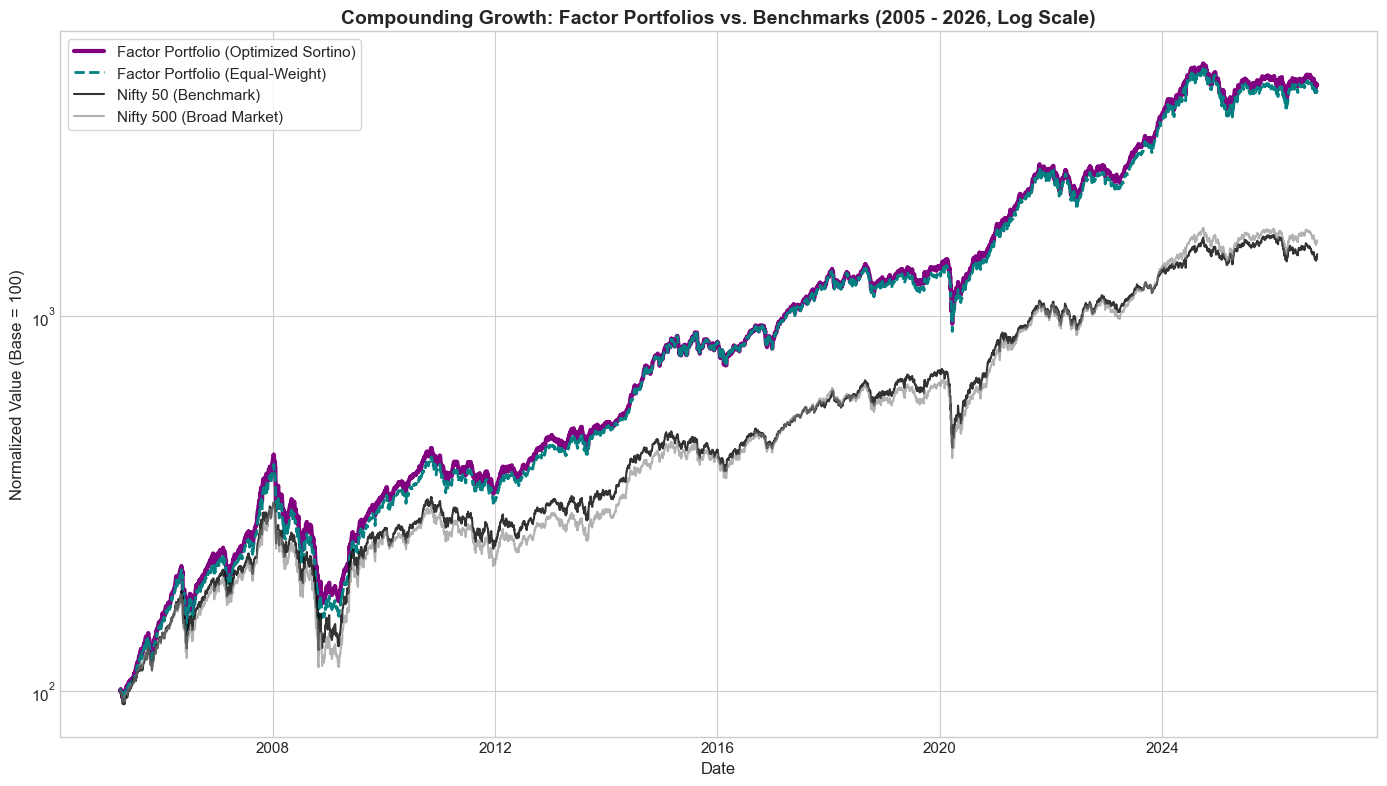

In [9]:
plt.figure(figsize=(14, 8))
plt.plot(combined_prices.index, (combined_prices["Factor Portfolio (Optimized Sortino)"] / combined_prices["Factor Portfolio (Optimized Sortino)"].iloc[0])*100, label="Factor Portfolio (Optimized Sortino)", color='purple', linewidth=3.0)
plt.plot(combined_prices.index, (combined_prices["Factor Portfolio (Equal-Weight)"] / combined_prices["Factor Portfolio (Equal-Weight)"].iloc[0])*100, label="Factor Portfolio (Equal-Weight)", color='teal', linewidth=2.0, linestyle='--')
plt.plot(combined_prices.index, (combined_prices["Nifty 50"] / combined_prices["Nifty 50"].iloc[0])*100, label="Nifty 50 (Benchmark)", color='black', linewidth=1.5, alpha=0.8)
plt.plot(combined_prices.index, (combined_prices["Nifty 500"] / combined_prices["Nifty 500"].iloc[0])*100, label="Nifty 500 (Broad Market)", color='gray', linewidth=1.5, alpha=0.6)

plt.yscale('log')
plt.title("Compounding Growth: Factor Portfolios vs. Benchmarks (2005 - 2026, Log Scale)", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalized Value (Base = 100)", fontsize=12)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "portfolio_performance_comparison.png"), dpi=300)
plt.show()

## 9. Insights, Observations & Recommendation Summary

Based on the outputs above (data refreshed to 16 Oct 2026):

### Core Findings
1. **Factor Premium is Real:** Every factor index compounded faster than the `Nifty 50` (CAGR **~13.3%**); the slowest factor index still delivered ~16.2%.
2. **Multi-Factor Leads on Risk-Adjusted Return:** `Nifty500 Multifactor MQVLv 50` has the best individual Sortino (**~1.11**) with a ~19.0% CAGR and a shallower max drawdown (-53.9%) than the Nifty 50 (-59.5%).
3. **The 3-Factor Blend Does Not Beat Low Volatility Alone:** The optimizer puts ~65% in Low Volatility and ~35% in Momentum (0% Quality). The blend's CAGR (~18.9%) is higher, but its Sortino (**~1.04**) is marginally *below* `Nifty500 Low Volatility 50` on its own (~1.05) and its drawdown is deeper (-60.2% vs -48.3%).
   - Caveat: the optimizer scores weekly-rebalanced arithmetic returns, while the plotted/metric portfolio is buy-and-hold from 2005, so the two are not the same portfolio. Weights are also fitted in-sample.
4. **Value Diversifies Only Modestly:** `Nifty200 Value 30` and `Nifty500 Value 50` correlate ~0.73-0.91 with the other indices (0.97 with each other) and carry the highest volatility of the factor set (~27%).
5. **Size Premium:** Nifty Midcap 150 (CAGR **~16.8%**) and Nifty Smallcap 250 (**~15.7%**) beat the Nifty 50, with much larger drawdowns (-72.9% and -75.6%).

### How to Achieve Better Long-Term CAGR Potential?
- **Factor tilts have historically beaten cap-weighting** in India over this sample, most clearly on a risk-adjusted basis.
- **Diversify factors, not just stocks:** combining Momentum with a defensive factor (Low Volatility / Quality) cuts the drawdowns of pure Momentum, which makes staying invested through a full cycle more realistic.
- Use the dashboard's **Deep Dive Compare** tab to check how consistent any edge is across rolling windows before relying on a point-to-point CAGR.
